In [23]:
import pandas as pds
import seaborn as sns

In [116]:
df = sns.load_dataset('iris')
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [117]:
from sklearn.preprocessing import LabelEncoder
encode = LabelEncoder()
df['species'] = encode.fit_transform(df['species'])

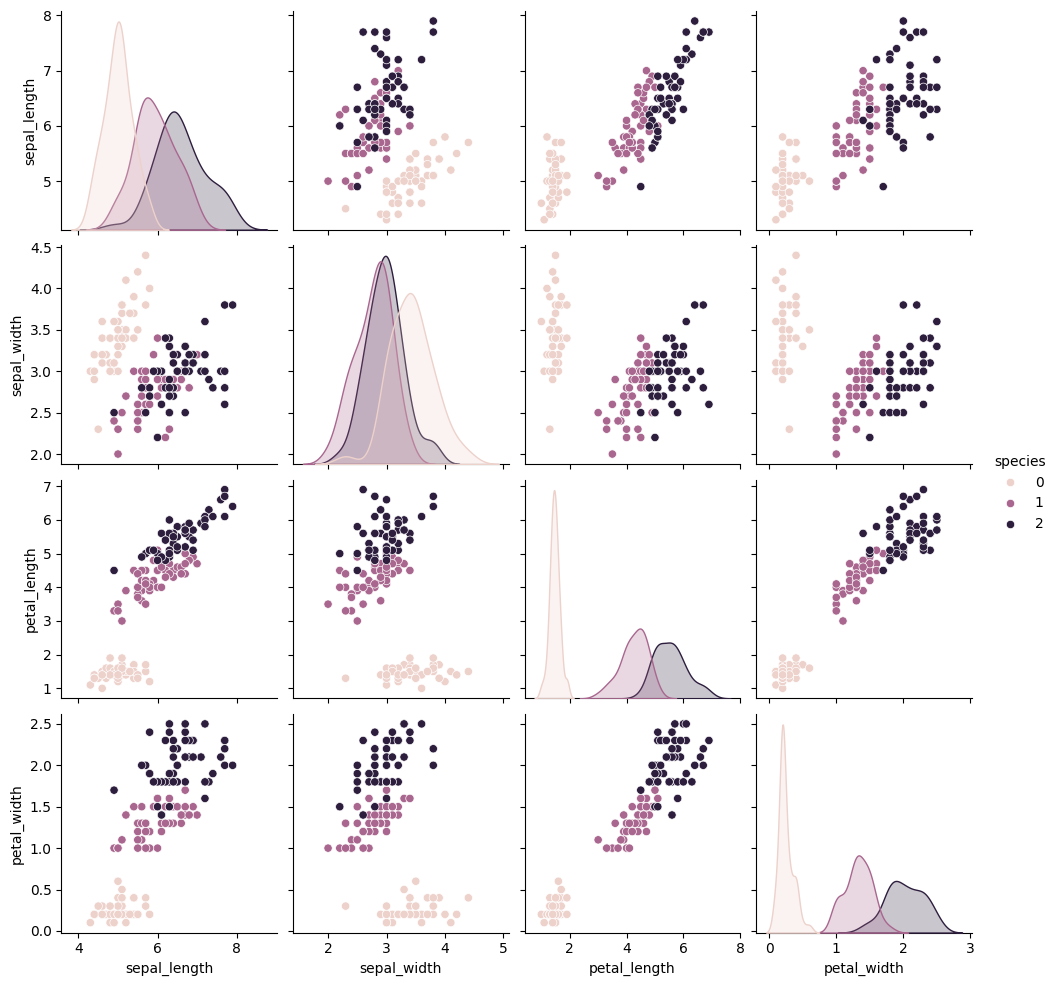

In [118]:
sns.pairplot(df,hue='species')

In [119]:
df = df[df['species'] != 0][['sepal_width','petal_length','species']]

In [120]:
df

,sepal_width,petal_length,species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1
...,...,...,...
145,3.0,5.2,2
146,2.5,5.0,2
147,3.0,5.2,2
148,3.4,5.4,2


In [121]:
X = df.iloc[:,0:3]
y = df['species']
df.columns

Index(['sepal_width', 'petal_length', 'species'], dtype='object')

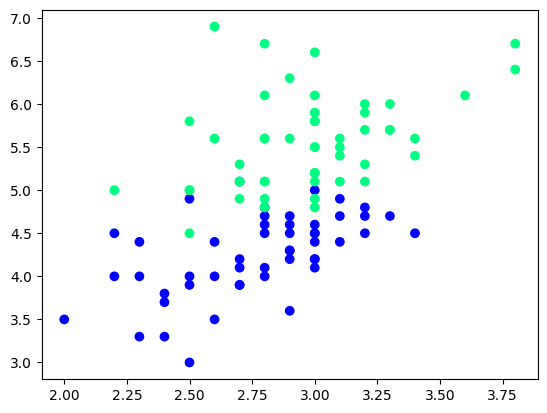

In [122]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.scatter(df['sepal_width'],df['petal_length'],c=df['species'],cmap='winter')

In [123]:
df_train = df.iloc[:60,:].sample(10)
df_train

,sepal_width,petal_length,species
94,2.7,4.2,1
107,2.9,6.3,2
109,3.6,6.1,2
86,3.1,4.7,1
89,2.5,4.0,1
63,2.9,4.7,1
79,2.6,3.5,1
54,2.8,4.6,1
96,2.9,4.2,1
85,3.4,4.5,1


In [163]:
# Taking only 10 rows for training
df = df_new.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [164]:
df

,sepal_length,sepal_width,species
139,6.9,3.1,2
148,6.2,3.4,2
121,5.6,2.8,2
62,6.0,2.2,1
61,5.9,3.0,1
...,...,...,...
74,6.4,2.9,1
51,6.4,3.2,1
106,4.9,2.5,2
66,5.6,3.0,1


In [165]:
df_train

,sepal_length,sepal_width,species
77,6.7,3.0,1
85,6.0,3.4,1
70,5.9,3.2,1
98,5.1,2.5,1
139,6.9,3.1,2
94,5.6,2.7,1
141,6.9,3.1,2
69,5.6,2.5,1
75,6.6,3.0,1
101,5.8,2.7,2


In [166]:
df_val

,sepal_length,sepal_width,species
83,6.0,2.7,1
58,6.6,2.9,1
76,6.8,2.8,1
133,6.3,2.8,2
140,6.7,3.1,2


In [167]:
df_test

,sepal_length,sepal_width,species
106,4.9,2.5,2
74,6.4,2.9,1
130,7.4,2.8,2
145,6.7,3.0,2
51,6.4,3.2,1


In [168]:

X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [169]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_length,sepal_width,species
98,5.1,2.5,1
141,6.9,3.1,2
139,6.9,3.1,2
98,5.1,2.5,1
141,6.9,3.1,2
77,6.7,3.0,1
70,5.9,3.2,1
77,6.7,3.0,1


In [170]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [171]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))
    

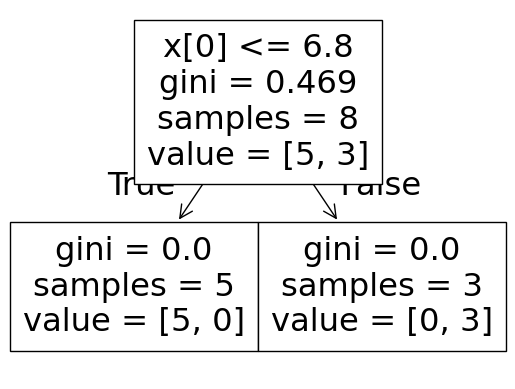

0.4


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


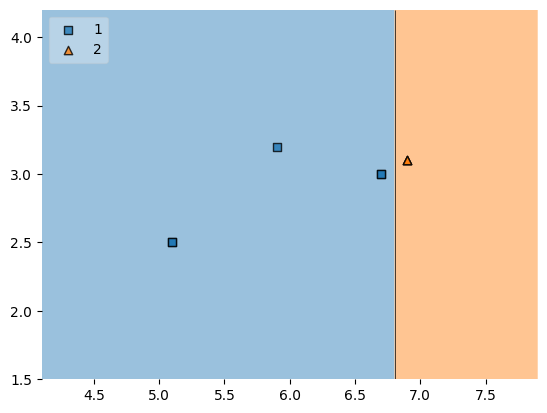

In [172]:
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

In [173]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_length,sepal_width,species
70,5.9,3.2,1
75,6.6,3.0,1
101,5.8,2.7,2
69,5.6,2.5,1
141,6.9,3.1,2
69,5.6,2.5,1
141,6.9,3.1,2
70,5.9,3.2,1


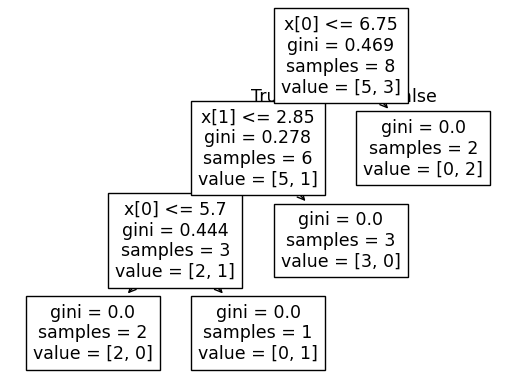

0.4


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


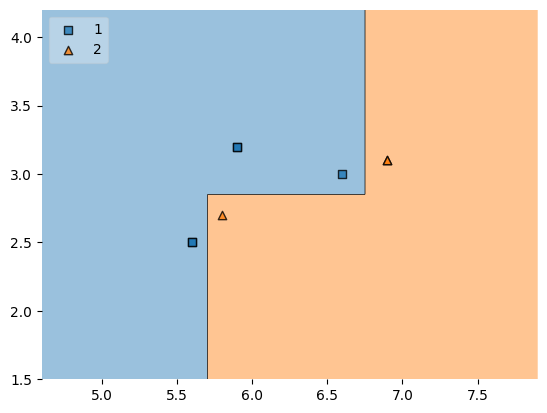

In [174]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [175]:
# Data for Tree 3
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_length,sepal_width,species
94,5.6,2.7,1
141,6.9,3.1,2
70,5.9,3.2,1
75,6.6,3.0,1
85,6.0,3.4,1
75,6.6,3.0,1
70,5.9,3.2,1
94,5.6,2.7,1


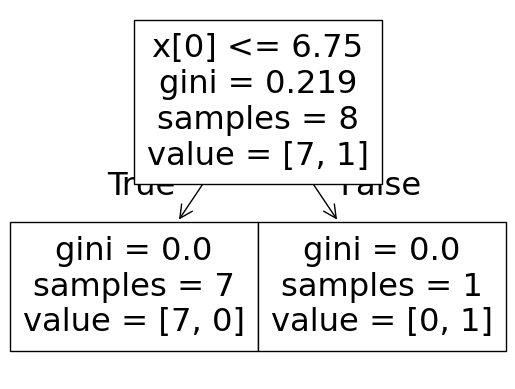

0.4


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


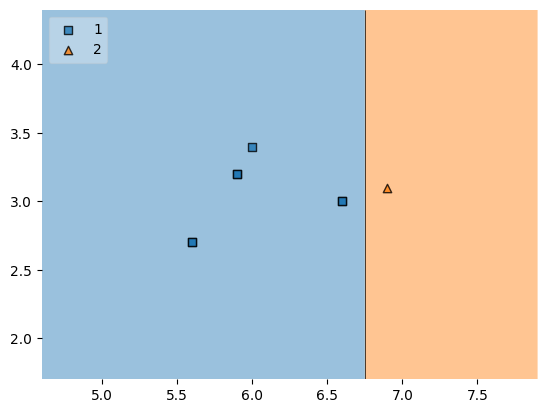

In [176]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [177]:
df_test

,sepal_length,sepal_width,species
106,4.9,2.5,2
74,6.4,2.9,1
130,7.4,2.8,2
145,6.7,3.0,2
51,6.4,3.2,1


In [178]:
print("Predictor 1",dt_bag1.predict(np.array([9,4]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([6.4,3.2]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([6.4,3.2]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [1]
Predictor 3 [1]


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
